In [5]:
from pathlib import Path

import pandas as pd

DATA_DIR = Path("../data/raw")

rates = pd.read_csv(DATA_DIR / "users_rates.csv")
anime = pd.read_csv(DATA_DIR / "anime.csv")
genres = pd.read_csv(DATA_DIR / "genres.csv")

In [6]:
rates.shape, anime.shape, genres.shape

((67071, 8), (9950, 16), (80, 3))

## Таблица `rates`

In [7]:
rates.head()
rates.dtypes

id           int64
score        int64
episodes     int64
rewatches    int64
createdAt      str
updatedAt      str
anime          str
user_id      int64
dtype: object


У полей `createdAt`, `updatedAt` пока текстовые даты - нужно будет их преобразовать.

Пока посмотрим на столбец `score` - оценка, которую поставил пользователь, при этом 0 означает, что пользователь не поставил никакую оценку, а не обозначил негативное мнение.

In [8]:
display(rates["score"].value_counts(dropna=False).sort_index())
display(rates.isna().sum())

score
0     38942
1       152
2       147
3       257
4       529
5      1211
6      2808
7      5374
8      6383
9      4551
10     6717
Name: count, dtype: int64

id           0
score        0
episodes     0
rewatches    0
createdAt    0
updatedAt    0
anime        0
user_id      0
dtype: int64

In [11]:
print("Пользователей в rates:", rates["user_id"].nunique())
print("Названий аниме в rates:", rates["anime"].nunique())
print("Названий аниме всего:", anime["id"].nunique())

Пользователей в rates: 1151
Названий аниме в rates: 4892
Названий аниме всего: 9949


Также столбец `anime` представлен в виде строки, а на самом деле там dict с id аниме. Для упрощения обработки надо:
- проверить что все строки только с одним id в anime
- распарсить значение в новый столбец anime_id

In [12]:
pattern = r"\{'id': '(\d+)'\}"

valid = rates["anime"].str.fullmatch(pattern, na=False)

print("Всего строк:", len(rates))
print("Ровно один числовой ID:", valid.sum())
print("Не прошли проверку:", (~valid).sum())

display(rates.loc[~valid, ["anime"]].head(10))

Всего строк: 67071
Ровно один числовой ID: 67071
Не прошли проверку: 0


,anime


In [13]:
rates["anime_id"] = (
    rates["anime"].str.extract(r"'id': '(\d+)'")[0].astype("int64")
)

In [14]:
rates = rates.drop(columns=["anime"])
rates.head()

,id,score,episodes,rewatches,createdAt,updatedAt,user_id,anime_id
0,203077117,0,12,0,2025-11-18T22:11:52+03:00,2025-11-18T22:12:03+03:00,1728717,53446
1,203077139,0,13,0,2025-11-18T22:12:22+03:00,2025-11-18T22:12:22+03:00,1728717,58172
2,203077171,0,12,0,2025-11-18T22:12:56+03:00,2025-11-18T22:12:56+03:00,1728717,43523
3,203077176,0,25,0,2025-11-18T22:13:02+03:00,2025-11-18T22:13:02+03:00,1728717,49889
4,203077216,0,11,0,2025-11-18T22:14:11+03:00,2025-11-18T22:14:11+03:00,1728717,41457


In [15]:
rates["createdAt"] = pd.to_datetime(rates["createdAt"], utc=True)
rates["updatedAt"] = pd.to_datetime(rates["updatedAt"], utc=True)

rates[["createdAt", "updatedAt"]].dtypes

createdAt    datetime64[us, UTC]
updatedAt    datetime64[us, UTC]
dtype: object

Проверим на сколько аниме дано оценок

In [18]:
in_catalog = rates["anime_id"].isin(anime["id"])

0        True
1        True
2        True
3        True
4        True
         ... 
67066    True
67067    True
67068    True
67069    True
67070    True
Name: anime_id, Length: 67071, dtype: bool

In [19]:
print("Количество аниме, на которые есть оценки и которые присутствуют в каталоге:", rates.loc[in_catalog, "anime_id"].nunique())
print("Отсутствуют в каталоге:", rates.loc[~in_catalog, "anime_id"].nunique())

Количество аниме, на которые есть оценки и которые присутствуют в каталоге: 4210
Отсутствуют в каталоге: 682


Отсортируем по парам user-anime

In [23]:
duplicate_pairs = rates.duplicated(
    ["user_id", "anime_id"], keep=False
)

print("Строк с повторяющимися парами:", duplicate_pairs.sum())

display(
    rates.loc[duplicate_pairs]
         .sort_values(["user_id", "anime_id", "updatedAt"])
)

Строк с повторяющимися парами: 12


,id,score,episodes,rewatches,createdAt,updatedAt,user_id,anime_id
12937,202635680,0,26,0,2025-11-08 19:54:55+00:00,2025-11-08 19:54:57+00:00,1721854,1
13053,203904508,0,0,0,2025-12-08 08:19:00+00:00,2025-12-08 08:19:00+00:00,1721854,1
15896,203475343,0,26,0,2025-11-27 21:45:36+00:00,2025-11-27 21:45:36+00:00,1732561,1
16010,203526384,0,0,0,2025-11-29 09:57:02+00:00,2025-11-29 09:57:02+00:00,1732561,1
50041,203628584,10,26,0,2025-12-01 15:08:44+00:00,2025-12-01 15:08:46+00:00,1734057,1
50181,203685206,10,0,0,2025-12-02 21:42:22+00:00,2025-12-02 21:47:24+00:00,1734057,1
44827,203996256,10,26,0,2025-12-10 11:36:50+00:00,2025-12-10 11:36:51+00:00,1737275,30
44908,203997120,0,0,0,2025-12-10 12:00:04+00:00,2025-12-10 12:00:04+00:00,1737275,30
33154,204744153,6,0,0,2025-12-26 02:49:34+00:00,2025-12-26 02:49:35+00:00,1743682,1
33162,205949362,7,26,0,2026-01-13 19:52:45+00:00,2026-01-13 19:53:35+00:00,1743682,1


Есть 6 нелогичных дублирований, так что удаляем дубликаты:

In [24]:
ambiguous = rates.duplicated(["user_id", "anime_id"], keep=False)
rates_unique = rates.loc[~ambiguous].copy()

print("Строк осталось:", len(rates_unique))
print(
    "Повторных пар осталось:",
    rates_unique.duplicated(["user_id", "anime_id"]).sum()
)

Строк осталось: 67059
Повторных пар осталось: 0


Посмотрим, сколько взаимодействий приходится на каждого пользователя и на каждое аниме

In [28]:
interactions_per_user = rates_unique.groupby("user_id")["anime_id"].nunique()
users_per_anime = rates_unique.groupby("anime_id")["user_id"].nunique()

display(interactions_per_user.describe())
display(users_per_anime.describe())

count    1151.000000
mean       58.261512
std        65.194360
min         1.000000
25%         5.000000
50%        31.000000
75%        92.500000
max       200.000000
Name: anime_id, dtype: float64

count    4892.00000
mean       13.70789
std        35.57883
min         1.00000
25%         1.00000
50%         3.00000
75%         9.00000
max       435.00000
Name: user_id, dtype: float64

Судя по среднему на пользователя приходится 31 взаимодействие и на 1 аниме 3 пользователя. Это показывает, что история многих аниме короткая.

Проверим логику дат

In [31]:
display(rates_unique[["createdAt", "updatedAt"]].agg(["min", "max"]))

days_per_user = (
    rates_unique.assign(day=rates_unique["createdAt"].dt.date)
    .groupby("user_id")["day"]
    .nunique()
)

print(
    "Пользователей, у которых все записи созданы в один день:",
    (days_per_user == 1).sum(),
    "из",
    len(days_per_user),
)

,createdAt,updatedAt
min,2025-11-07 19:14:34+00:00,2025-11-07 19:14:52+00:00
max,2026-02-23 08:38:24+00:00,2026-02-23 08:38:29+00:00


Пользователей, у которых все записи созданы в один день: 669 из 1151


In [32]:
active_users = interactions_per_user[
    interactions_per_user >= 10
].index

print(
    "Все записи за один день при ≥10 взаимодействиях:",
    (days_per_user.loc[active_users] == 1).sum(),
    "из",
    len(active_users),
)

Все записи за один день при ≥10 взаимодействиях: 378 из 786


378 из 786 пользователей с >= 10 взаимодействиями (48%) имеют все записи в один день. Это может означать массовое добавление аниме в список; по createdAt пока нельзя уверенно восстановить дни просмотра.
Проверим, за сколько часов создавались записи у таких пользователей:

In [33]:
user_dates = rates_unique.groupby("user_id")["createdAt"].agg(["min", "max"])
span_hours = (
    user_dates["max"] - user_dates["min"]
).dt.total_seconds() / 3600

one_day_active = active_users[
    days_per_user.loc[active_users] == 1
]

display(span_hours.loc[one_day_active].describe())
print(
    "Уложились в один час:",
    (span_hours.loc[one_day_active] <= 1).sum(),
    "из",
    len(one_day_active),
)

count    378.000000
mean       1.209575
std        2.127690
min        0.000000
25%        0.218819
50%        0.502917
75%        1.171389
max       15.645556
dtype: float64

Уложились в один час: 270 из 378


у 270 из 378 активных пользователей, чьи записи попали в один день, они были созданы в пределах часа. Медиана: около 30 минут между добавлениями. Похоже на массовое добавление записей; считать createdAt временем просмотра без дополнительного подтверждения нельзя.

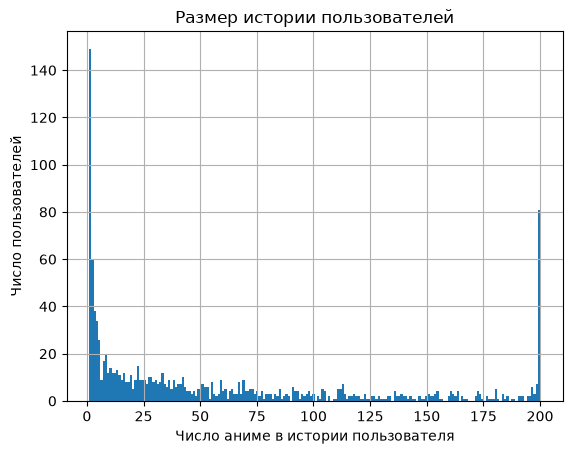

In [35]:
import matplotlib.pyplot as plt

interactions_per_user.hist(bins=200)
plt.xlabel("Число аниме в истории пользователя")
plt.ylabel("Число пользователей")
plt.title("Размер истории пользователей")
plt.show()

## Таблица `anime`

Проверим таблицу `anime` на уникальность

In [20]:
display(anime.loc[anime["id"].duplicated(keep=False), ["id", "name", "russian"]])

,id,name,russian
7849,10917,Pokemon: Pikachu no Fuyuyasumi (2001),Покемон: Пикачу зимой (2001)
7850,10917,Pokemon: Pikachu no Fuyuyasumi (2001),Покемон: Пикачу зимой (2001)


In [22]:
anime = anime.drop_duplicates().reset_index(drop=True)

print("Строк:", len(anime))
print("ID уникальны:", anime["id"].is_unique)

Строк: 9949
ID уникальны: True


In [29]:
display(anime.dtypes)
display(anime.isna().sum().sort_values(ascending=False))

id                 int64
name                 str
russian              str
description          str
score            float64
rating               str
episodes           int64
episodesAired      int64
duration           int64
genres               str
season               str
airedOn              str
releasedOn           str
status               str
studios              str
isCensored          bool
dtype: object

season           5608
description      4161
russian            13
name                0
score               0
rating              0
episodes            0
id                  0
episodesAired       0
duration            0
genres              0
airedOn             0
releasedOn          0
status              0
studios             0
isCensored          0
dtype: int64

После удаления дубликата в anime пропущены season у 5 608 аниме (56%), description у 4 161 (42%) и russian у 13. При этом id и name заполнены у всех: записи можно связать с взаимодействиями, поэтому удалять следующие строки не нужно.

## Таблица `genres`

In [21]:
display(genres.loc[genres["id"].duplicated(keep=False), ["id", "name"]])

,id,name


In [30]:
display(genres.dtypes)
display(genres.isna().sum().sort_values(ascending=False))

id         int64
name         str
russian      str
dtype: object

id         0
name       0
russian    0
dtype: int64